# MATH840 Final project, Session 1

Tuesday 3 November 2026. Submit `SURNAME_project.csv` on Moodle by **11:30**.

You work as a data scientist at an energy company. You have the hourly electricity generation of its
portfolio, with the weather, up to midnight on 27 October 2026. Your task is to forecast the next 48
hours, hour by hour, with a 95% prediction interval.

This notebook loads the data, defines the scores, computes the benchmark and writes the submission file.
You choose and build the model yourself.

The submission cell starts from the benchmark. If you run the notebook from top to bottom first, you
will have a valid file within five minutes, and you can use the rest of the session to beat it.

## 0. Setup

Download `train.csv` and `weather_forecast.csv` from Moodle. In Colab, the next cell asks you to upload
them. On your own machine, put them in the same folder as the notebook.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 120, "display.precision", 3)

SURNAME = "Narbut"   # <-- for your submission file name

if not SURNAME.strip():
    raise ValueError("Set SURNAME before running the rest.")

In [2]:
NEEDED = ["train.csv", "weather_forecast.csv"]

if not all(Path(f).exists() for f in NEEDED):
    try:
        from google.colab import files
        files.upload()                       # choose both files at once
    except ImportError:
        raise FileNotFoundError(f"Put {NEEDED} next to this notebook.")

data = pd.read_csv("train.csv", parse_dates=["ds"])
weather_fc = pd.read_csv("weather_forecast.csv", parse_dates=["ds"])

H = 48                                       # hours to forecast
M = 24                                       # the benchmark's season: one day
FUTURE = weather_fc["ds"]

assert len(FUTURE) == H and FUTURE.iloc[0] == data["ds"].iloc[-1] + pd.Timedelta(hours=1)
print(f"history: {len(data)} hours, {data['ds'].min()} to {data['ds'].max()}")
print(f"you are forecasting: {FUTURE.iloc[0]} to {FUTURE.iloc[-1]}")
data.tail()

history: 33480 hours, 2023-01-01 01:00:00 to 2026-10-27 00:00:00
you are forecasting: 2026-10-27 01:00:00 to 2026-10-29 00:00:00


,ds,y,cloud_cover,temperature,wind_speed,pressure,humidity,daylight,air_density
33475,2026-10-26 20:00:00,42.5,1.0,9,3,763,87,0,1.259
33476,2026-10-26 21:00:00,76.7,1.0,9,4,763,87,0,1.259
33477,2026-10-26 22:00:00,65.8,1.0,7,3,763,100,0,1.268
33478,2026-10-26 23:00:00,69.9,1.0,7,3,763,100,0,1.268
33479,2026-10-27 00:00:00,69.9,1.0,7,3,763,100,0,1.268


### The data

| Column | Meaning |
|---|---|
| `ds` | the hour |
| `y` | electricity generated in that hour; this is what you forecast |
| `cloud_cover` | from 0 (clear) to 1 (overcast), in steps of 0.25 |
| `temperature` | °C |
| `wind_speed` | m/s |
| `pressure` | mm Hg |
| `humidity` | % |
| `daylight` | 1 while the sun is above the horizon |
| `air_density` | kg/m³ |

`train.csv` has the weather as it was. `weather_forecast.csv` has a forecast for the 48 hours you
predict, of the kind a weather service issues. Its errors grow from the first day to the second.

## 1. How you are scored

Your file gets three scores on the 48 hidden hours, and lower is better for each. RMSE measures the
point forecast in the units of `y`, and MAPE measures it in percent of the actual value. The Winkler
score measures the 95% interval: its width, plus 40 times ($2/\alpha$) the distance by which the actual
value falls outside it.

The benchmark is a seasonal naive forecast with a daily season. Each hour of the next two days gets the
value of the same hour on the last day you have. Its 95% interval is the standard one for seasonal naive,
$\hat y \pm 1.96\,\hat\sigma\sqrt{k+1}$, where $k$ is the number of full days into the horizon.

The project description on Moodle explains the points and the leaderboard.

In [3]:
def rmse(actual, forecast) -> float:
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(forecast)) ** 2)))


def mape(actual, forecast) -> float:
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    return float(np.mean(np.abs((actual - forecast) / actual)) * 100)


def winkler(actual, lower, upper, alpha: float = 0.05) -> float:
    actual, lower, upper = (np.asarray(a, float) for a in (actual, lower, upper))
    below = np.clip(lower - actual, 0, None)
    above = np.clip(actual - upper, 0, None)
    return float(np.mean((upper - lower) + 2 / alpha * (below + above)))


def score(actual, forecast, lower, upper) -> dict:
    inside = (np.asarray(actual) >= lower) & (np.asarray(actual) <= upper)
    return {"RMSE": rmse(actual, forecast), "MAPE": mape(actual, forecast),
            "Winkler": winkler(actual, lower, upper), "coverage": float(inside.mean())}


def snaive(history: np.ndarray, h: int = H, m: int = M):
    # The benchmark: repeat the last season, with the seasonal-naive 95% interval.
    history = np.asarray(history, float)
    point = np.array([history[-m + (i % m)] for i in range(h)])
    sigma = np.std(history[m:] - history[:-m], ddof=1)
    k = np.arange(h) // m
    half = 1.96 * sigma * np.sqrt(k + 1)
    return point, np.clip(point - half, 0, None), point + half

### The benchmark on a validation window

You cannot score a forecast on the hidden hours, so the cell below holds back the last 48 hours of the
history, forecasts them from the hours before, and scores the result. This is a single window. You can
decide how much more validation you need.

In [4]:
y = data["y"].to_numpy(float)
past, valid = y[:-H], y[-H:]

bench = snaive(past)
results = pd.DataFrame({"seasonal naive": score(valid, *bench)}).T
results

,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.0


## 2. My model, its validation, and the report

This notebook is the code and the report at the same time. The four questions of the brief are answered in
**Q1–Q4** below. The model code lives in `forecast_lib.py`; `run_backtest.py` regenerates the 150-origin
backtest (`backtest_final.csv`, 40–60 min on 8 cores) and `make_forecast.py` writes the submission file
(the same steps as section 3 here). With `backtest_final.csv` present, this notebook runs in a few minutes.

**Summary.** One LightGBM for all 48 horizons, trained on *noisy* weather (to mimic the weather forecast),
with features that follow the solar clock across the end-of-October clock change and that tell the model the
current capacity of a fast-growing portfolio. The point forecast is the mean of a model of `y` and a model of
`y / 28-day level`. The 95% interval is asymmetric and scales with the forecast and with recent volatility.
The last two steps are tuned for the leaderboard, which ranks students per metric rather than averaging
scores. Small forecasts are shrunk, because MAPE punishes over-forecasting calm, near-zero nights, and the
interval is 10% narrower than calibrated, because that beats the calibrated one on most days.

On 150 held-out daily origins (29 May – 25 Oct 2026, with simulated forecast weather), on hours 25–48, with
seasonal naive and my Session 1 model in brackets:

| | new | seasonal naive | Session 1 model |
|---|---|---|---|
| RMSE | 191 | 272 | 224 |
| MAPE | 89% | 225% | 145% |
| Winkler | 944 | 1850 | 1101 |
| coverage | 0.91 | 0.86 | 0.95 |

The calibrated version of the interval scores 916 at 0.95 coverage. In a simulation of the leaderboard against
12 competitor forecasts, the submitted settings improve the expected rank from 4.50 to 4.18 (out of 13).

In [5]:
import forecast_lib as fl
import make_forecast as mf

RUN_BACKTEST = False          # True: recompute the 150-origin backtest (40-60 minutes)
BT_FILE = "backtest_final.csv"
d = data.assign(hour=data.ds.dt.hour, month=data.ds.dt.to_period("M"))

### Q1. What is in the series?

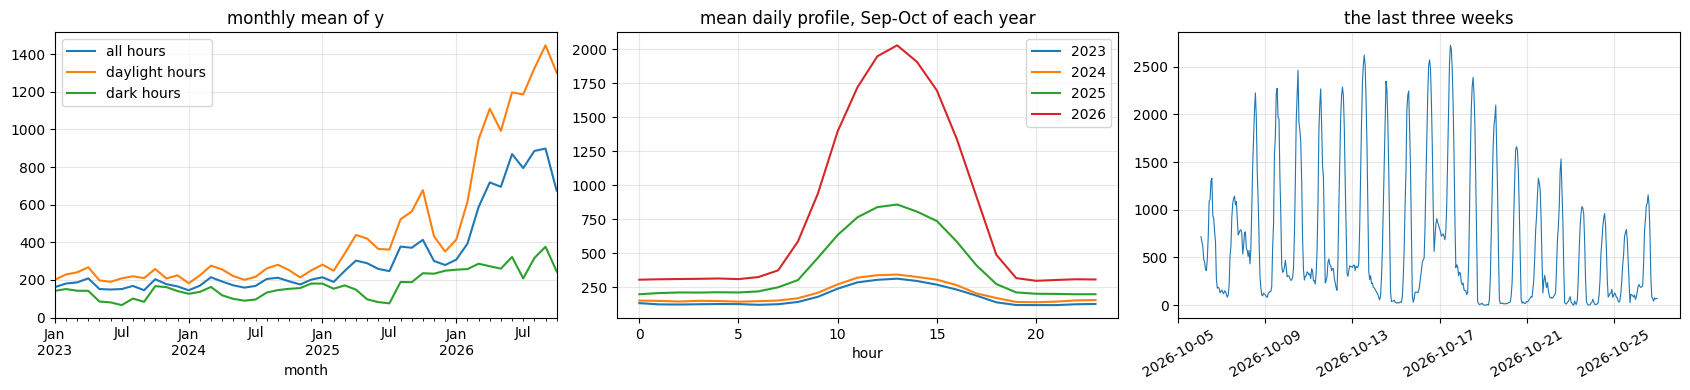

,all hours,daylight hours,dark hours
month,,,
2023-12-31,171.0,221.0,122.0
2024-12-31,184.0,236.0,133.0
2025-12-31,291.0,417.0,167.0
2026-12-31,682.0,1053.0,280.0


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
m = pd.DataFrame({"all hours": d.groupby("month").y.mean(),
                  "daylight hours": d[d.daylight == 1].groupby("month").y.mean(),
                  "dark hours": d[d.daylight == 0].groupby("month").y.mean()})
m.index = m.index.to_timestamp()
m.plot(ax=ax[0], title="monthly mean of y")
for yr in [2023, 2024, 2025, 2026]:
    s = d[(d.ds.dt.year == yr) & d.ds.dt.month.isin([9, 10])]
    s.groupby("hour").y.mean().plot(ax=ax[1], label=str(yr))
ax[1].legend(); ax[1].set_title("mean daily profile, Sep-Oct of each year")
last = data[data.ds > data.ds.max() - pd.Timedelta(days=21)]
ax[2].plot(last.ds, last.y, lw=0.8); ax[2].set_title("the last three weeks"); ax[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
m.resample("YE").mean().round(0)

**Solar plus wind, growing fast.** The daytime hump is solar, and the dark hours are wind. Output has grown four- to
fivefold, almost all of it in the solar part: the daylight-hour mean went from about 230 (2023–24) to about 1,300
(Aug–Oct 2026), while the dark-hour mean went from about 130 to about 300. A tree model cannot extrapolate a level it
has never seen, so the model is given the *current* level at the forecast origin (means over the last 7 and 28 days,
separately for daylight and dark hours), and half of the ensemble predicts `y / 28-day level` instead of `y`.

**Late October is volatile.** Foggy days peak at 800–1,100 and clear days at about 2,500. Calm nights fall almost to
zero (0.7–3 on 19 and 23 Oct), and windy nights reach about 800.

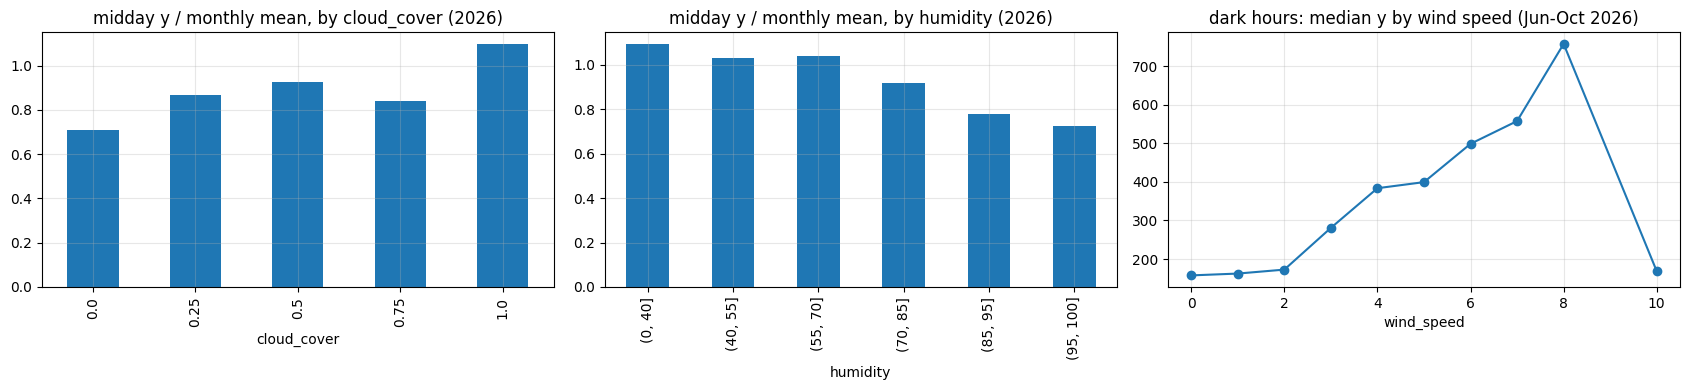

,cloud_cover,humidity,temperature,wind_speed
cloud_cover,1.00,-0.42,0.33,-0.11
humidity,-0.42,1.00,-0.67,-0.17
temperature,0.33,-0.67,1.00,-0.03
wind_speed,-0.11,-0.17,-0.03,1.00


In [7]:
mid = d[(d.hour >= 11) & (d.hour <= 14) & (d.ds >= "2026-01-01")].copy()
mid["rel"] = mid.y / mid.groupby("month").y.transform("mean")
dark = d[(d.daylight == 0) & (d.ds >= "2026-06-01")]
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
mid.groupby("cloud_cover").rel.mean().plot(ax=ax[0], kind="bar", title="midday y / monthly mean, by cloud_cover (2026)")
mid.groupby(pd.cut(mid.humidity, [0, 40, 55, 70, 85, 95, 100])).rel.mean().plot(
    ax=ax[1], kind="bar", title="midday y / monthly mean, by humidity (2026)")
dark.groupby("wind_speed").y.median().plot(ax=ax[2], marker="o", title="dark hours: median y by wind speed (Jun-Oct 2026)")
plt.tight_layout(); plt.show()
data[["cloud_cover", "humidity", "temperature", "wind_speed"]].corr().round(2)

**Weather.** `cloud_cover` behaves as if it were *inverted*: midday output is highest at `cloud_cover = 1`, and
`cloud_cover` correlates −0.42 with humidity and +0.33 with temperature (real cloud cover goes the other way). Trees
learn the sign either way. Humidity is the clearer signal: at 95–100% (fog) midday output is about 25% below
normal. In the dark hours, output follows wind speed roughly cubically. The model uses the hourly weather, its
centred 3-hour mean, and the mean over the daylight hours of the same day (a robust "type of day").

daylight window around the autumn clock change in train:
   2024-10-24:08-16 2024-10-25:08-16 2024-10-26:08-16 2024-10-27:07-15 2024-10-28:07-15 2024-10-29:07-15
   2025-10-24:08-16 2025-10-25:08-16 2025-10-26:08-16 2025-10-27:07-15 2025-10-28:07-15 2025-10-29:07-15
   2026-10-21:08-16 2026-10-22:08-16 2026-10-23:08-16 2026-10-24:08-16 2026-10-25:08-16 2026-10-26:08-16
weather_forecast.csv: {datetime.date(2026, 10, 27): '07-15', datetime.date(2026, 10, 28): '07-15'}


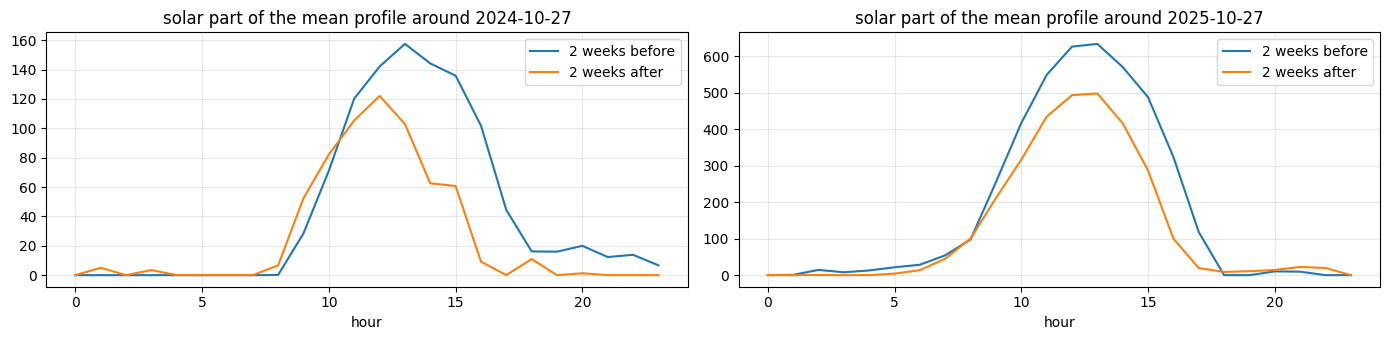

In [8]:
dl = data[data.daylight == 1].assign(date=lambda x: (x.ds - pd.Timedelta(hours=1)).dt.date)
win = dl.groupby("date").ds.agg(lambda s: f"{s.dt.hour.min():02d}-{s.dt.hour.max():02d}")
print("daylight window around the autumn clock change in train:")
for a, b in [("2024-10-24", "2024-10-29"), ("2025-10-24", "2025-10-29"), ("2026-10-21", "2026-10-26")]:
    print("  ", " ".join(f"{k}:{v}" for k, v in win.loc[pd.Timestamp(a).date():pd.Timestamp(b).date()].items()))
fwin = weather_fc[weather_fc.daylight == 1].groupby(weather_fc.ds.dt.date).ds.agg(lambda s: f"{s.dt.hour.min():02d}-{s.dt.hour.max():02d}")
print("weather_forecast.csv:", dict(fwin))

fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
for i, c in enumerate(["2024-10-27", "2025-10-27"]):
    c = pd.Timestamp(c)
    for lab, lo, hi in [("2 weeks before", c - pd.Timedelta(days=14), c), ("2 weeks after", c, c + pd.Timedelta(days=14))]:
        s = d[(d.ds > lo) & (d.ds <= hi)].groupby("hour").y.mean()
        (s - s.loc[[0, 1, 2, 3, 22, 23]].mean()).clip(lower=0).plot(ax=ax[i], label=lab)
    ax[i].set_title(f"solar part of the mean profile around {c.date()}"); ax[i].legend()
plt.tight_layout(); plt.show()

**The clock change falls on the first forecast day.** In every year the daylight window moves from 08–16 to
07–15 on 27–28 October, and the solar curve moves with it. `weather_forecast.csv` already shows 07–15 for both
forecast days, but the last day of `train.csv` still shows 08–16. A model built on clock hour and "the same hour
yesterday" would carry the bright 16:00 value of the last training day into a dark 16:00. I therefore use
`solar_hour` = hour − middle of the daylight window, and I take the seasonal-naive input at the same *solar* hour
of the reference day (`sn_al`). Hours are hour-ending, so 00:00 is treated as the last hour of the previous day.

In [9]:
sub = data[data.ds.dt.dayofyear.between(270, 335)]
full = pd.concat([data.tail(1), weather_fc], ignore_index=True)
rows = {}
for c in ["cloud_cover", "temperature", "wind_speed", "pressure", "humidity"]:
    act = (sub[c].diff() ** 2).mean()
    fd = full[c].diff().iloc[1:]
    d1, d2 = (fd.iloc[:24] ** 2).mean(), (fd.iloc[24:] ** 2).mean()
    rows[c] = {"actual: mean sq. hourly change": act, "forecast day 1": d1, "forecast day 2": d2,
               "implied noise sd, day 1": np.sqrt(max(d1 - act, 0) / 2),
               "implied noise sd, day 2": np.sqrt(max(d2 - act, 0) / 2), "sd used, day 1 / day 2": fl.SIG[c]}
pd.DataFrame(rows).T.round(3)

,actual: mean sq. hourly change,forecast day 1,forecast day 2,"implied noise sd, day 1","implied noise sd, day 2","sd used, day 1 / day 2"
cloud_cover,0.051,0.016,0.094,0.0,0.145,"(0.1, 0.25)"
temperature,1.47,3.708,11.333,1.058,2.221,"(1.0, 2.2)"
wind_speed,1.188,0.333,1.5,0.0,0.395,"(0.5, 1.0)"
pressure,0.347,0.333,6.083,0.0,1.694,"(0.5, 1.7)"
humidity,34.456,4.5,43.417,0.0,2.117,"(3.0, 6.0)"


**The weather forecast is noisy, more so on day 2.** Hour to hour, the forecast is much rougher than the actual
weather (temperature jumps 7 → 10 → 5 → 18). Independent noise adds 2σ² to the mean squared hourly change, so
the excess roughness gives the noise size: temperature σ ≈ 1.1 on day 1 and 2.2 on day 2, pressure σ ≈ 1.7 on
day 2, and so on. These are lower bounds, since smooth errors do not show up in hourly changes, so I use slightly
larger values for cloud, wind and humidity. The noise model is used twice. **(1) Backtest:** the 48 hours get the
actual weather plus simulated noise, so validation scores pay for weather-forecast errors (the Session 1 backtest
used the actual weather and was optimistic). **(2) Training:** each horizon copy of the training set gets noise of
its own lead time, so the model learns how far to trust a forecast that is 1 or 2 days old.

### The model

* **One stacked model for all horizons.** Each training row is a pair (target hour *t*, horizon *h*), with
  *h* ∈ {1, 6, 12, …, 48}. Its features are of two kinds:
  * the target hour: hour, day of year, `solar_hour`, day length, the 7 weather variables, `daylight·(1−cloud)`,
    `daylight·cloud`, `ρ·wind³`, centred 3-hour means, and daylight-hour means of the day;
  * the origin *t − h*: the last value; the means of the last 6/24/72/168/672 hours; the dark- and daylight-hour
    means over the last 7 and 28 days; the 7-day max; the 28-day 90% quantile; and the DST-aligned seasonal-naive
    value `sn_al`.
* **Two targets, averaged.** Raw `y`, and `y / (mean of the last 28 days)`. The ratio is close to stationary
  despite the growth, which a tree cannot extrapolate. Their mean is the point forecast.
* **Trained on noisy weather.** See Q1.
* **LightGBM:** 600 trees, learning rate 0.05, 63 leaves, at least 200 rows per leaf (each hour appears nine times
  in the stacked data, so smaller leaves memorise single hours), 70% of the features and 80% of the rows per tree.
* **MAPE-aware point:** forecasts below 500 are multiplied by `smin + (1 − smin)·f/500`, with `smin` = 0.6
  (see Q2 and the rank section).
* **Interval:** see Q3. Its width is ×0.9 of the calibrated one for the ranking (see the rank section).

In [10]:
print(len(fl.COLS), "features:", ", ".join(fl.COLS))
print("weather noise sd (day 1, day 2):", fl.SIG)

37 features: hour, doy, solar_hour, day_len, cloud_cover, temperature, wind_speed, pressure, humidity, daylight, air_density, clear_day, cloud_day, wind3, cloud_cover_r3, humidity_r3, temperature_r3, wind_speed_r3, cloud_cover_dmean, humidity_dmean, temperature_dmean, wind_dmean, wind3_dmean, h, sn_al, last, lvl6, lvl24, lvl72, lvl168, lvl672, night168, day168, night672, day672, max168, q90_672
weather noise sd (day 1, day 2): {'cloud_cover': (0.1, 0.25), 'temperature': (1.0, 2.2), 'wind_speed': (0.5, 1.0), 'pressure': (0.5, 1.7), 'humidity': (3.0, 6.0), 'air_density': (0.01, 0.014)}


### Q2. How did I check the forecast before submitting it?

**Design.** I used 150 daily origins at midnight, from 29 May to 25 Oct 2026. Each is the real task in miniature:
the history up to 00:00, and a forecast for 01:00 to 00:00 two days later. Every model is refit on the data before
its origin. The 48 hours get the *simulated forecast weather* described in Q1, with a fixed seed per origin, so every
model sees the same noise. Since the ranking uses hours 25–48 only, I report day 1 and day 2 separately and chose
the model on day 2. The table also shows my Session 1 model, re-run in the same backtest. All scores are means over
the origins of the per-origin score, as on the leaderboard.

In [11]:
if RUN_BACKTEST or not Path(BT_FILE).exists():
    import run_backtest
    run_backtest.main(out=BT_FILE)
bt = pd.read_csv(BT_FILE, parse_dates=["ds"])
bt = fl.add_vol(fl.add_groups(bt), data.y, data.daylight)
print(bt.E.nunique(), "origins:", bt.ds.min(), "to", bt.ds.max())

def table(bt, cols, names):
    out = {}
    for c, nm in zip(cols, names):
        for dd in (1, 2):
            s = fl.per_origin_scores(bt, c, day=dd)
            sn = fl.per_origin_scores(bt, "sn", day=dd)
            out[(nm, f"day {dd}")] = {"RMSE": s.RMSE.mean(), "MAPE": s.MAPE.mean(), "median MAPE": s.MAPE.median(),
                                      "beats snaive (RMSE)": f"{int((s.RMSE.values < sn.RMSE.values).sum())}/{len(s)}"}
    return pd.DataFrame(out).T

table(bt, ["sn", "orig", "raw", "ratio", "final"],
      ["seasonal naive", "Session 1 model", "new: raw target", "new: ratio target", "new: mean of the two"]).round(1)

150 origins: 2026-05-29 01:00:00 to 2026-10-27 00:00:00


RMSE     MAPE median MAPE beats snaive (RMSE)
seasonal naive       day 1  232.071  103.577      41.664               0/150
                     day 2  272.337  224.717      44.688               0/150
Session 1 model      day 1  188.644   80.588      33.277             108/150
                     day 2  223.924  144.646       39.47             102/150
new: raw target      day 1  170.506   65.341      29.843             119/150
                     day 2  198.012   125.16      33.073             116/150
new: ratio target    day 1  172.309   60.561      30.038             114/150
                     day 2  193.868   94.644      33.762             117/150
new: mean of the two day 1  165.652   61.918      29.533             121/150
                     day 2  190.748  109.406      32.292             117/150

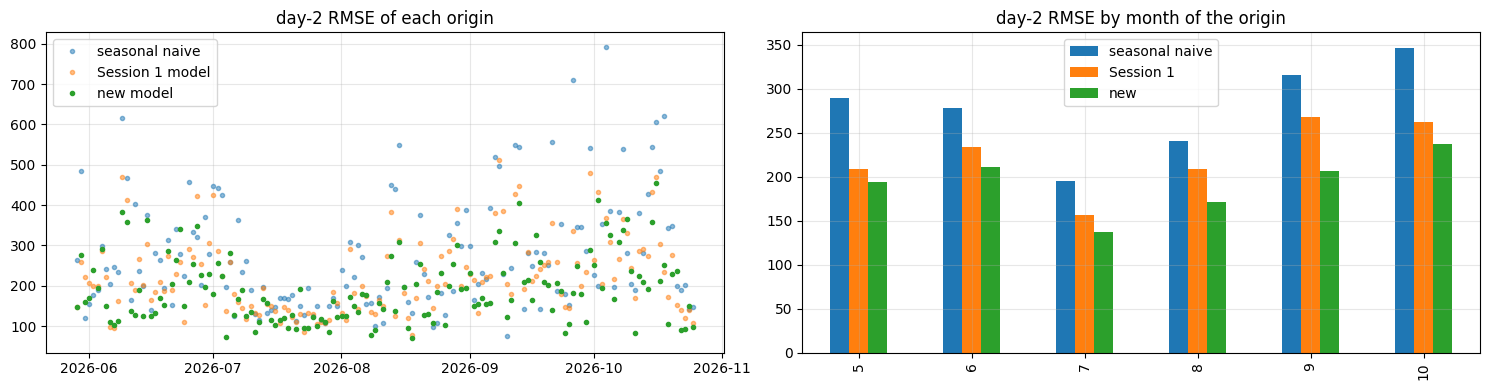

In [12]:
sn2 = fl.per_origin_scores(bt, "sn", day=2).set_index("E")
s1 = fl.per_origin_scores(bt, "orig", day=2).set_index("E")
nw = fl.per_origin_scores(bt, "final", day=2).set_index("E")
start = bt.groupby("E").ds.min()
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].plot(start.loc[nw.index], sn2.RMSE, ".", alpha=0.5, label="seasonal naive")
ax[0].plot(start.loc[nw.index], s1.RMSE, ".", alpha=0.5, label="Session 1 model")
ax[0].plot(start.loc[nw.index], nw.RMSE, "o", ms=3, label="new model")
ax[0].set_title("day-2 RMSE of each origin"); ax[0].legend()
mon = start.loc[nw.index].dt.month.values
pd.DataFrame({"seasonal naive": sn2.RMSE.values, "Session 1": s1.RMSE.values, "new": nw.RMSE.values}).groupby(mon).mean().plot(
    ax=ax[1], kind="bar", title="day-2 RMSE by month of the origin")
plt.tight_layout(); plt.show()

**What the backtest shows.** On day 2 the new model's RMSE is about 191, against 272 for seasonal naive and 224
for my Session 1 model. It beats seasonal naive on 117 of 150 origins. The two targets have similar RMSE, and their
mean is better than either (their errors differ: the ratio model reacts to the level, and the raw model to the
weather). The new model wins in every month, but October is the hardest month for all three. The error grows in
October while the level falls, because foggy and clear days alternate and calm nights fall almost to zero.

The model choices were made step by step on 60 origins (every third day), always with simulated forecast weather.
On that set, the original model scored a day-2 RMSE of 219. New features brought it to 205, training on noisy
weather to 195, the solar alignment and the ratio-target mean to 186, and the regularised trees kept 186 with a
better MAPE. The 150-origin run is the final check, with the settings frozen.

**MAPE needs its own point.** MAPE divides by the actual value. On calm nights the output can be 1–20 when any
forecast says about 100, so a handful of hours dominate the mean. In October, the 5% of day-2 hours with an
actual value below 20 carry 77% of the summed APE. For such hours the MAPE-optimal point lies far below the mean.
I multiply forecasts below 500 by `smin + (1 − smin)·f/500`, and leave larger ones alone.

The table shows the trade-off. Minimising log RMSE + 0.5·log MAPE would pick `smin` = 0.4. I submit 0.6
because the leaderboard ranks rather than averages. With `smin` = 0.6 the shrink still beats no shrink on MAPE
on about two days in three, but it costs fewer RMSE places. The rank section below has the simulation.

In [13]:
b2 = bt[bt.day == 2]
rows = []
for smin in [1.0, 0.8, 0.6, 0.5, 0.4, 0.3, 0.2]:
    p = fl.ramp(b2.final.to_numpy(), smin, 500)
    g = pd.DataFrame({"E": b2.E, "a": b2.actual, "p": p}).groupby("E")
    rows.append({"smin": smin, "day-2 RMSE": g.apply(lambda x: fl.rmse(x.a, x.p), include_groups=False).mean(),
                 "day-2 MAPE": g.apply(lambda x: fl.mape(x.a, x.p), include_groups=False).mean()})
pd.DataFrame(rows).set_index("smin").round(1)

,day-2 RMSE,day-2 MAPE
smin,,
1.0,190.7,109.4
0.8,190.4,99.0
0.6,191.3,89.2
0.5,192.2,84.5
0.4,193.3,80.1
0.3,194.8,75.9
0.2,196.5,72.0


### Q3. How good is the interval?

**The recipe.** The interval is built separately for four groups: daylight or dark hours, on day 1 or day 2. Within
a group, the distances from the point forecast *f* to the 2.5% and 97.5% quantiles are `a·vol + b·f`. Here *vol*
is the RMS day-to-day change of `y` over the 14 days before the origin, computed separately for daylight and dark
hours. The coefficients are quantile (pinball-loss) regressions of the backtest residuals, with *b* ≥ 0.

* The interval is **asymmetric.** A dark-hour forecast of 80 cannot miss by much on the low side, but it can on
  the high side.
* The **b·f** term widens the interval on bright, high-output hours, where a wrong fog/clear call costs the most.
* The **a·vol** term widens it in volatile periods. An interval calibrated over the whole summer was too narrow
  for October: coverage 0.88, Winkler 1350 on day 2. With the volatility term, October reaches 0.92 and 1136.

**The check.** I used leave-one-origin-out: the coefficients for each origin come from the other 149. As a
stricter variant, only origins whose 48 hours had ended before it were used. The MAPE shrink is fitted the same
way. The Session 1 recipe (a symmetric radius, the 95% quantile of |error| in 10 groups) is evaluated the same
way.

In [14]:
L = fl.loo_pipeline(bt, "final")                        # as submitted: smin 0.6, width x0.9
L1 = fl.loo_pipeline(bt, "final", width=1.0)            # the calibrated interval
P = fl.loo_pipeline(bt, "final", past_only=True).dropna(subset=["point"])

def sym10(bt, col):            # the Session 1 interval: 95% quantile of |error| by 5 parts of the day x day
    part = pd.cut(bt.ds.dt.hour, [-1, 5, 8, 15, 19, 23], labels=False).astype(str) + "_" + bt.day.astype(str)
    lo = np.empty(len(bt)); hi = np.empty(len(bt))
    for E in bt.E.unique():
        tr, te = (bt.E != E).to_numpy(), (bt.E == E).to_numpy()
        rad = (bt.actual - bt[col])[tr].abs().groupby(part[tr]).quantile(0.95)
        r = part[te].map(rad).to_numpy()
        lo[te] = np.clip(bt[col].to_numpy()[te] - r, 0, None); hi[te] = bt[col].to_numpy()[te] + r
    return bt.assign(s1_lo=lo, s1_hi=hi)

S = sym10(bt, "orig")
res = {}
for dd in (1, 2):
    for nm, frame, p, lo, hi in [("seasonal naive", bt, "sn", "sn_lo", "sn_hi"),
                                 ("Session 1 model + its interval", S, "orig", "s1_lo", "s1_hi"),
                                 ("new, calibrated interval (x1.0)", L1, "point", "lo", "hi"),
                                 ("new, as submitted (x0.9)", L, "point", "lo", "hi"),
                                 ("new, as submitted, past origins only", P, "point", "lo", "hi")]:
        s = fl.per_origin_scores(frame, p, lo, hi, day=dd)
        res[(nm, f"day {dd}")] = s[["RMSE", "MAPE", "Winkler", "coverage", "width"]].mean()
pd.DataFrame(res).T.round(3)

,,RMSE,MAPE,Winkler,coverage,width
seasonal naive,day 1,232.071,103.577,1880.387,0.777,563.629
Session 1 model + its interval,day 1,188.644,80.588,939.662,0.948,757.447
"new, calibrated interval (x1.0)",day 1,166.027,49.037,821.999,0.946,690.716
"new, as submitted (x0.9)",day 1,166.027,49.037,847.951,0.910,622.002
"new, as submitted, past origins only",day 1,167.018,49.649,852.966,0.913,626.067
seasonal naive,day 2,272.337,224.717,1850.379,0.860,771.600
Session 1 model + its interval,day 2,223.924,144.646,1100.643,0.948,887.158
"new, calibrated interval (x1.0)",day 2,191.303,89.155,916.348,0.946,784.624
"new, as submitted (x0.9)",day 2,191.303,89.155,943.763,0.913,706.505
"new, as submitted, past origins only",day 2,191.094,91.157,949.822,0.913,707.653


In [15]:
L1["month"] = L1.groupby("E").ds.transform("min").dt.month
rows = {}
for mo, g in L1.groupby("month"):
    s = fl.per_origin_scores(g, "point", "lo", "hi", day=2)
    sn = fl.per_origin_scores(g, "sn", "sn_lo", "sn_hi", day=2)
    rows[mo] = {"origins": len(s), "coverage": s.coverage.mean(), "Winkler": s.Winkler.mean(), "snaive Winkler": sn.Winkler.mean(),
                "width": s.width.mean(), "mean y": g[g.day == 2].actual.mean()}
print("day 2 by month of the origin (calibrated interval)"); pd.DataFrame(rows).T.round(2)

day 2 by month of the origin (calibrated interval)


,origins,coverage,Winkler,snaive Winkler,width,mean y
5,3.0,0.99,799.06,2258.61,789.65,627.78
6,30.0,0.92,985.49,1666.72,786.87,885.26
7,31.0,0.99,720.56,1137.82,699.18,783.06
8,31.0,0.94,803.67,1312.66,709.55,885.09
9,30.0,0.95,994.48,2393.52,854.51,908.20
10,25.0,0.92,1136.19,2920.35,896.51,661.44


**Reading the numbers.** The calibrated interval does what it should. On day 2 it covers 94.6% of hours,
against a target of 95%. Its Winkler score is about 916, half the 1,850 of seasonal naive and 17% below the 1,101
of the Session 1 recipe. It is also narrower than the Session 1 interval (785 against 887), because it is wide
only where the errors are.

October is the weakest month. Coverage there is 0.92 and the Winkler score about 1,140. Late October has more
calm-to-windy and fog-to-clear switches than the summer, which makes up most of the history.

**The submitted interval is ×0.9 of the calibrated one.** It covers about 91% of hours and scores a mean Winkler
of 944. The mean is slightly worse than 916, but the median is better (778 against 832), and the narrower
interval wins on 64% of days. On the leaderboard only the order matters, so winning most days is what counts. Two
further points support the choice:

* The narrower interval loses badly only on the rare stormy day, and a bad day costs at most a few places.
* My Session 1 file still counts if it scores better, and its wide interval already covers the stormy case.

The next section puts numbers on this.

### Tuning for the leaderboard rank

The final ranking is 0.3·rank(RMSE) + 0.3·rank(MAPE) + 0.4·rank(Winkler) on hours 25–48, so what matters is beating
other students on that day, not the average score. I simulate it on the 150 backtest days.

**The field.** Twelve competitor forecasts that differ from mine:
* seasonal naive with its interval;
* my Session 1 model;
* the Session 1 building blocks (A with and without lags, B);
* each of my two single models on its own;
* a 50/50 blend with seasonal naive;
* a version 15% too high and one 10% too low.

Each competitor gets a typical interval: a conformal radius per part of the day (the Session 1 recipe), or
±1.96 residual sd.

**The calculation.** On each day, my file gets a rank in each metric among the 13 forecasts (1 = best), and the
ranks are combined with the leaderboard weights. The field is only a stand-in for the real class, but it is
diverse: from seasonal naive to models of my own quality.

In [16]:
field = fl.competitor_field(L1)
grid = []
for smin in [1.0, 0.8, 0.65, 0.6, 0.5, 0.4]:
    for width in [0.85, 0.9, 0.95, 1.0, 1.1]:
        R = fl.simulate_rank(L1, field, smin, width)
        grid.append({"smin": smin, "width": width, "mean rank": R.combined.mean(), "P(top 3 of 13)": (R.combined <= 3).mean(),
                     "rank RMSE": R.RMSE.mean(), "rank MAPE": R.MAPE.mean(), "rank Winkler": R.W.mean(),
                     "P(RMSE < seasonal naive)": R["beats snaive RMSE"].mean()})
grid = pd.DataFrame(grid)
print("mean combined rank (1 = best of 13), rows: smin, columns: interval width")
display(grid.pivot(index="smin", columns="width", values="mean rank").round(2))
grid.sort_values("mean rank").head(6).round(3)

mean combined rank (1 = best of 13), rows: smin, columns: interval width


width,0.85,0.90,0.95,1.00,1.10
smin,,,,,
0.40,4.45,4.35,4.39,4.50,4.98
0.50,4.34,4.24,4.28,4.39,4.87
0.60,4.28,4.18,4.22,4.33,4.81
0.65,4.27,4.16,4.21,4.32,4.80
0.80,4.33,4.23,4.27,4.39,4.87
1.00,4.60,4.50,4.54,4.65,5.13


,smin,width,mean rank,P(top 3 of 13),rank RMSE,rank MAPE,rank Winkler,P(RMSE < seasonal naive)
11,0.65,0.90,4.164,0.400,4.367,4.34,3.880,0.787
16,0.60,0.90,4.176,0.380,4.467,4.28,3.880,0.780
12,0.65,0.95,4.209,0.360,4.367,4.34,3.993,0.787
17,0.60,0.95,4.221,0.347,4.467,4.28,3.993,0.780
6,0.80,0.90,4.228,0.387,4.400,4.52,3.880,0.780
21,0.50,0.90,4.236,0.393,4.567,4.38,3.880,0.780


**Result.** The best region is `smin` ≈ 0.6–0.65 with the interval at ×0.9. The table is flat there, so I
take the round values 0.6 and ×0.9. Against the earlier settings (`smin` = 0.4, ×1.0) the expected rank improves
from 4.50 to 4.18, and the chance of a top-3 day rises from 29% to 38%.

The tuning does not touch the chance of being ranked at all. Beating seasonal naive on RMSE stays at 78% of
days. It should be higher on 28 October, because seasonal naive repeats 26 October one clock hour off across the
clock change, so its ramps are misplaced (for example 767 at 16:00, when the sun has set).

Rank optimisation shrinks the interval only a little, by 10%. A much narrower interval loses more ranks on its bad
days than it gains on the good ones.

### Q4. What is left, and what did not work?

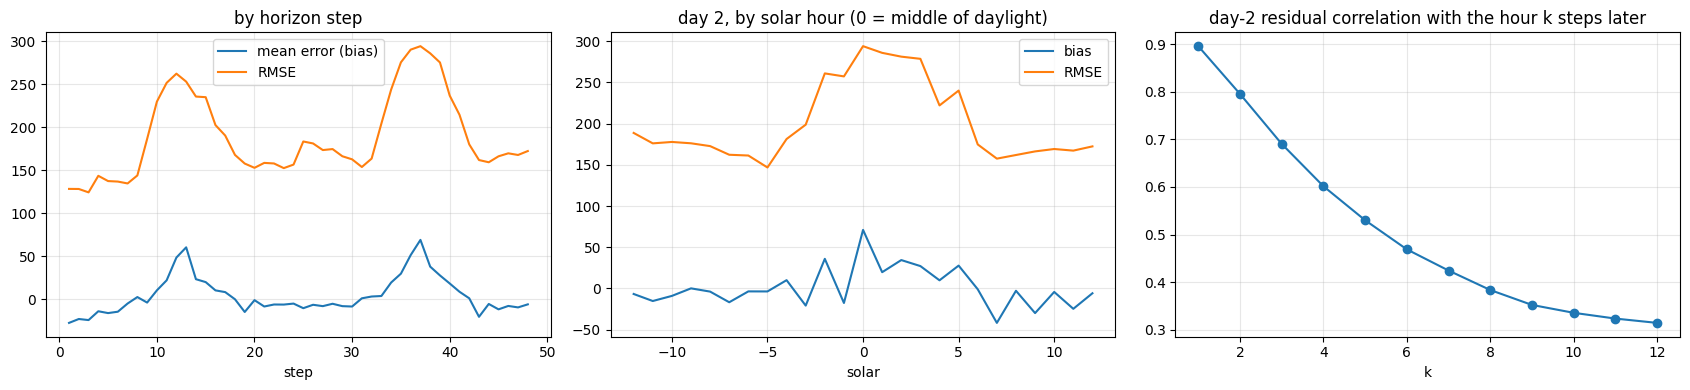

day-2 residual quantiles: {0.01: np.float64(-486.0), 0.025: np.float64(-403.0), 0.25: np.float64(-123.0), 0.5: np.float64(-9.0), 0.75: np.float64(132.0), 0.975: np.float64(443.0), 0.99: np.float64(535.0)}  skew: 0.28


In [17]:
solar_of = pd.Series(fl.hour_feats(data).solar_hour.to_numpy(), index=data.ds)
R = L1.assign(res=L1.actual - L1.final, solar=np.round(L1.ds.map(solar_of)))
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
g = R.groupby("step").res
pd.DataFrame({"mean error (bias)": g.mean(), "RMSE": g.apply(lambda r: np.sqrt(np.mean(r ** 2)))}).plot(ax=ax[0], title="by horizon step")
R[R.day == 2].groupby("solar").res.agg(["mean", lambda r: np.sqrt(np.mean(r ** 2))]).set_axis(["bias", "RMSE"], axis=1).plot(
    ax=ax[1], title="day 2, by solar hour (0 = middle of daylight)")
piv = R[R.day == 2].pivot_table(index="E", columns="step", values="res")
ax[2].plot(range(1, 13), [piv.corrwith(piv.shift(-k, axis=1)).mean() for k in range(1, 13)], marker="o")
ax[2].set_title("day-2 residual correlation with the hour k steps later"); ax[2].set_xlabel("k")
plt.tight_layout(); plt.show()
q = R[R.day == 2].res.quantile([0.01, 0.025, 0.25, 0.5, 0.75, 0.975, 0.99]).round(0)
print("day-2 residual quantiles:", dict(q), " skew:", round(R[R.day == 2].res.skew(), 2))

**Residuals.**

* **Bias.** Before the shrink, the day-2 mean error is +7, so there is no growth bias left. The Session 1 model
  under-forecast by about 30, and the 28-day ratio target is what fixed it. After the shrink the point is low on
  purpose at small values.
* **Where the error sits.** It peaks in the middle of the daylight window. The fog/clear call dominates, and it
  rests on a humidity and cloud forecast that is noisy on day 2.
* **Autocorrelation.** Errors are strongly correlated from hour to hour: 0.9 one hour apart, about 0.5 six hours
  apart, and 0.3 twelve hours apart. A wrong call about the day shifts the whole afternoon, so the 24 errors of a
  day behave like a few independent errors rather than 24. This is why the per-day RMSE varies so much between
  origins, and why a single day says little about a model.
* **Tails and scale.** The pooled day-2 errors have slightly heavy tails. With σ taken from the interquartile
  range (≈ 189), the 2.5% / 97.5% quantiles sit at −2.1σ / +2.3σ, against ±1.96σ for a normal, and the distribution
  is a little right-skewed. More important, the scale changes with the hour, the forecast level and the period.
  That is why the interval uses empirical quantiles that scale with *f* and *vol*, rather than a fixed ±1.96σ.

What is left is mostly weather information that the data do not contain. That includes whether the fog lifts, and
the size of the real forecast errors, which I could only estimate from the roughness of the file.

**Tried and dropped** (on the 60-origin set with simulated forecast weather unless noted; day-2 scores):

| idea | result | why dropped |
|---|---|---|
| a separate model trained only on horizons 24–48 | RMSE 197.9 vs 194.6 for all horizons | fewer and less varied rows |
| recency weights (half-life 120 or 365 days) | RMSE 189.3, MAPE 99 vs 186.3 / 79 | the level features already carry the regime |
| 14-day same-solar-hour profile features (mean, max, min) | ensemble RMSE 187.2 vs 186.3 | redundant with `sn_al` and the levels |
| trend feature `t` in the stacked model | RMSE 206.1 vs 205.0 | trees cannot extrapolate it, and the levels do the job |
| log target | MAPE 56 but RMSE 227 and bias +114 | the explicit shrink gives a better trade-off |
| bigger trees (127 leaves, 400 rows per leaf, L2) | RMSE 186.2, MAPE 90 vs 186.1 / 76 | no gain, slower |
| point × factor > 1 for large forecasts (bias fix) | the fit chose ×1.00 | — |
| interval from recent windows only (30 or 60), or with recency weights | Winkler 1118–1151 vs 1100 (past-only, last 60) | noisier quantiles |
| interval with a 7/21/28-day volatility window | Winkler 1055–1068 vs 1043 (14 days) | — |
| dark-hour interval piecewise in *f* | better overall (728 vs 755), worse in October (872–939 vs 831) | October is what matters |
| quantile regression on recent solar potential | no consistent gain | — |
| interval × 1.1 (150 origins, leave-one-out) | Winkler 931 vs 916, wins fewer days | — (×0.9 is kept for the rank, see above) |
| interval also conditioned on 7-day volatility, forecast wind (dark hours) or forecast humidity (day hours) | blocked CV, day 2: Winkler 928–934 vs 926; past-only 914–921 vs 913 | no gain over 14-day volatility + forecast |
| a stronger MAPE shrink (`smin` 0.4, the log-score optimum) | MAPE 80 vs 89, RMSE 193 vs 191; simulated rank 4.35 vs 4.18 (both at ×0.9) | costs more RMSE places than it gains in MAPE |
| *Session 1 work (from my earlier notes):* training on the last 365 days only; a level-normalised direct model on its own; a 20% seasonal-naive blend | worse or no gain | — |


## 3. Submission

Replace the benchmark in the first line with your own forecast. `forecast`, `lower_95` and `upper_95`
are arrays of 48 numbers, one for each hour in `FUTURE`, in order. Generation cannot be negative, so the
lower bound must be 0 or above.

shrink: smin=0.60, f0=500; interval width x0.9; origin volatility day=318, dark=246
  dark_d1   lower = f - (0.21*vol + 0.62*f)   upper = f + (1.56*vol + 0.00*f)
  dark_d2   lower = f - (0.12*vol + 0.80*f)   upper = f + (1.46*vol + 0.25*f)
  light_d1  lower = f - (0.67*vol + 0.12*f)   upper = f + (1.02*vol + 0.12*f)
  light_d2  lower = f - (0.72*vol + 0.18*f)   upper = f + (1.27*vol + 0.10*f)


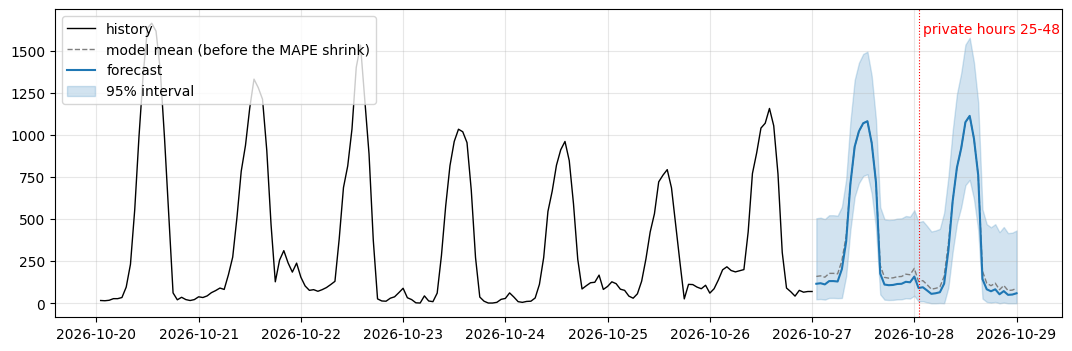

,ds,raw,ratio,final,forecast,lower_95,upper_95
0,2026-10-27 01:00:00,169.8,148.7,159.2,115.8,23.8,504.4
1,2026-10-27 02:00:00,184.6,141.1,162.9,118.9,25.4,508.0
2,2026-10-27 03:00:00,193.7,115.6,154.6,111.9,21.8,499.8
3,2026-10-27 04:00:00,197.9,157.0,177.4,131.6,31.7,522.6
4,2026-10-27 05:00:00,193.4,161.7,177.6,131.8,31.8,522.7
5,2026-10-27 06:00:00,192.1,157.4,174.7,129.3,30.6,519.9
6,2026-10-27 07:00:00,274.4,231.3,252.9,202.9,31.5,572.5
7,2026-10-27 08:00:00,460.9,335.9,398.4,366.0,160.7,734.4
8,2026-10-27 09:00:00,786.8,630.3,708.6,708.6,435.9,1079.5
9,2026-10-27 10:00:00,927.0,931.9,929.4,929.4,632.0,1325.2


In [18]:
detail = mf.forecast(data, weather_fc, pd.read_csv(BT_FILE, parse_dates=["ds"]))
forecast, lower_95, upper_95 = detail.forecast.to_numpy(), detail.lower_95.to_numpy(), detail.upper_95.to_numpy()

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(data["ds"].iloc[-7 * M:], y[-7 * M:], color="black", lw=1, label="history")
ax.plot(FUTURE, detail.final, color="tab:gray", ls="--", lw=1, label="model mean (before the MAPE shrink)")
ax.plot(FUTURE, forecast, color="tab:blue", label="forecast")
ax.fill_between(FUTURE, lower_95, upper_95, color="tab:blue", alpha=0.2, label="95% interval")
ax.axvline(FUTURE.iloc[24], color="red", lw=0.8, ls=":"); ax.text(FUTURE.iloc[25], ax.get_ylim()[1] * 0.92, "private hours 25-48", color="red")
ax.legend(loc="upper left")
plt.show()
detail.round(1)

In [19]:
def check_submission(sub: pd.DataFrame) -> None:
    assert list(sub.columns) == ["ds", "forecast", "lower_95", "upper_95"], "wrong columns"
    assert len(sub) == H, f"need {H} rows, got {len(sub)}"
    assert (pd.to_datetime(sub["ds"]).to_numpy() == FUTURE.to_numpy()).all(), "the hours do not match FUTURE"
    assert sub[["forecast", "lower_95", "upper_95"]].notna().all().all(), "missing values"
    assert (sub["lower_95"] >= 0).all(), "a lower bound is negative"
    assert (sub["lower_95"] <= sub["forecast"]).all() and (sub["forecast"] <= sub["upper_95"]).all(), \
        "the forecast must lie inside its interval"
    print("format OK")


submission = pd.DataFrame({"ds": FUTURE.dt.strftime("%Y-%m-%d %H:%M:%S"), "forecast": forecast,
                           "lower_95": lower_95, "upper_95": upper_95})
check_submission(submission)

FILE = f"{SURNAME.strip().upper()}_project.csv"
submission.to_csv(FILE, index=False)
print("saved", FILE)

try:
    from google.colab import files
    files.download(FILE)
except ImportError:
    pass

format OK
saved NARBUT_project.csv


Upload `SURNAME_project.csv` to the *Session 1* activity on Moodle by **11:30**. You can upload more than
once, and the last file before 11:30 counts, so submit the benchmark early and replace it if you find
something better.

After the session you can keep working on the forecast at home. The project description on Moodle has
the details.